In [1]:
## Football Player Market Value Prediction

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [2]:
from google.colab import files
uploaded = files.upload()

Saving footballers.csv to footballers.csv


In [3]:
df = pd.read_csv('footballers.csv')
df = df.replace(['nan', 'NaN', 'NAN', ''], np.nan)
print(df)

                    Name  Age Nationality  Overall  Potential  \
0      Cristiano Ronaldo   32    Portugal       90         92   
1               L. Messi   30   Argentina       95         96   
2                 Neymar   25      Brazil       92         94   
3              L. Suárez   30     Uruguay       92         92   
4               M. Neuer   31     Germany       92         92   
...                  ...  ...         ...      ...        ...   
17976          A. Kelsey   17     England       46         63   
17977      B. Richardson   47     England       46         46   
17978           J. Young   17    Scotland       46         61   
17979       J. Lundstram   18     England       46         64   
17980          L. Sackey   18       Ghana       46         64   

                      Club   Value   Wage  Special Acceleration  ...    RB  \
0           Real Madrid CF  €95.5M  €565K     2228           89  ...  61.0   
1             FC Barcelona   €105M  €565K     2154           92

In [4]:
# analysis
print(df.columns)
print(df.shape)
print(df.info())
print(df.describe())
print(df.duplicated().sum())

print(df['Nationality'].nunique())
print(df['Nationality'].value_counts())

print(df['Club'].nunique())
print(df['Club'].value_counts())


print(df['Preferred Positions'].value_counts())

print(df['Wage'].head())
print(df['Wage'].dtype)

print(df['Value'].head())       # Target analysis
print(df['Value'].dtype)

print(df.isnull().sum())

Index(['Name', 'Age', 'Nationality', 'Overall', 'Potential', 'Club', 'Value',
       'Wage', 'Special', 'Acceleration', 'Aggression', 'Agility', 'Balance',
       'Ball control', 'Composure', 'Crossing', 'Curve', 'Dribbling',
       'Finishing', 'Free kick accuracy', 'GK diving', 'GK handling',
       'GK kicking', 'GK positioning', 'GK reflexes', 'Heading accuracy',
       'Interceptions', 'Jumping', 'Long passing', 'Long shots', 'Marking',
       'Penalties', 'Positioning', 'Reactions', 'Short passing', 'Shot power',
       'Sliding tackle', 'Sprint speed', 'Stamina', 'Standing tackle',
       'Strength', 'Vision', 'Volleys', 'CAM', 'CB', 'CDM', 'CF', 'CM', 'LAM',
       'LB', 'LCB', 'LCM', 'LDM', 'LF', 'LM', 'LS', 'LW', 'LWB',
       'Preferred Positions', 'RAM', 'RB', 'RCB', 'RCM', 'RDM', 'RF', 'RM',
       'RS', 'RW', 'RWB', 'ST'],
      dtype='object')
(17981, 70)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17981 entries, 0 to 17980
Data columns (total 70 columns):
 #   Col

In [5]:
def convert_money(x):
    x = x.replace('€','')

    if 'M' in x:
        return float(x.replace('M',''))*1000000
    elif 'K' in x:
        return float(x.replace('K',''))*1000
    else:
        return float(x)

df['Value'] = df['Value'].apply(convert_money)
df['Wage'] = df['Wage'].apply(convert_money)

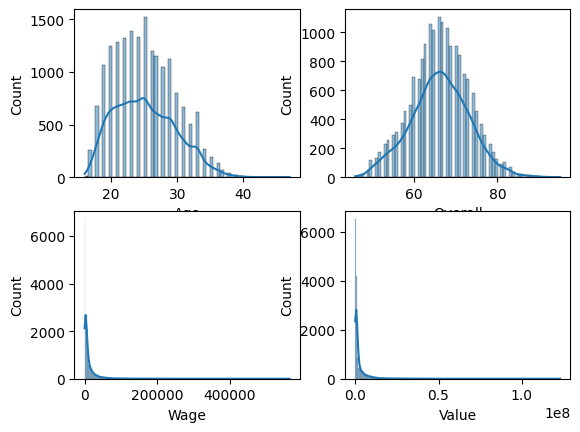

In [6]:

def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde = True)


plotting('Age',1)
plotting('Overall',2)
plotting('Wage',3)
plotting('Value',4)
plt.show()

In [7]:
df['Elite'] = (df['Overall'] >= 90).astype(int)     # Feature Engineering

print(df[df['Elite'] == 1]['Name'])
print(df[df['Elite'] == 1]['Nationality'].value_counts())
print(df[df['Elite'] == 1]['Club'].value_counts())

0     Cristiano Ronaldo
1              L. Messi
2                Neymar
3             L. Suárez
4              M. Neuer
5        R. Lewandowski
6                De Gea
7             E. Hazard
8              T. Kroos
9            G. Higuaín
10         Sergio Ramos
Name: Name, dtype: object
Nationality
Argentina    2
Germany      2
Spain        2
Portugal     1
Uruguay      1
Brazil       1
Poland       1
Belgium      1
Name: count, dtype: int64
Club
Real Madrid CF         3
FC Barcelona           2
FC Bayern Munich       2
Paris Saint-Germain    1
Manchester United      1
Chelsea                1
Juventus               1
Name: count, dtype: int64


In [8]:
for col in df.columns:
    print(f"{col}: {df[col].isnull().sum()}")       # shows which colm have how many null

position_cols = [
    'CAM','CB','CDM','CF','CM','LAM','LB','LCB','LCM','LDM',
    'LF','LM','LS','LW','LWB','RAM','RB','RCB','RCM','RDM',
    'RF','RM','RS','RW','RWB','ST'
]                                                            # fills the null position. now only the clubs colm have null value

df[position_cols] = df[position_cols].fillna(0)

df['Club'] = df['Club'].fillna('Free Agent')            # no null clubs

for col in df.columns:
    print(f"{col}: {df[col].isnull().sum()}")       # Checking again

Name: 0
Age: 0
Nationality: 0
Overall: 0
Potential: 0
Club: 248
Value: 0
Wage: 0
Special: 0
Acceleration: 0
Aggression: 0
Agility: 0
Balance: 0
Ball control: 0
Composure: 0
Crossing: 0
Curve: 0
Dribbling: 0
Finishing: 0
Free kick accuracy: 0
GK diving: 0
GK handling: 0
GK kicking: 0
GK positioning: 0
GK reflexes: 0
Heading accuracy: 0
Interceptions: 0
Jumping: 0
Long passing: 0
Long shots: 0
Marking: 0
Penalties: 0
Positioning: 0
Reactions: 0
Short passing: 0
Shot power: 0
Sliding tackle: 0
Sprint speed: 0
Stamina: 0
Standing tackle: 0
Strength: 0
Vision: 0
Volleys: 0
CAM: 2029
CB: 2029
CDM: 2029
CF: 2029
CM: 2029
LAM: 2029
LB: 2029
LCB: 2029
LCM: 2029
LDM: 2029
LF: 2029
LM: 2029
LS: 2029
LW: 2029
LWB: 2029
Preferred Positions: 0
RAM: 2029
RB: 2029
RCB: 2029
RCM: 2029
RDM: 2029
RF: 2029
RM: 2029
RS: 2029
RW: 2029
RWB: 2029
ST: 2029
Elite: 0
Name: 0
Age: 0
Nationality: 0
Overall: 0
Potential: 0
Club: 0
Value: 0
Wage: 0
Special: 0
Acceleration: 0
Aggression: 0
Agility: 0
Balance: 0
Ball 

In [9]:
# converting to numeric values
exclude = ['Name', 'Nationality', 'Club', 'Preferred Positions']

"""
we have found that some places instead of 11-10 it is made 11-Oct. so have to change that into 11-10.
"""
month_map = {
    'Jan': 1, 'Feb': 2, 'Mar': 3, 'Apr': 4,
    'May': 5, 'Jun': 6, 'Jul': 7, 'Aug': 8,
    'Sep': 9, 'Oct': 10, 'Nov': 11, 'Dec': 12
}

def convert_date(x):

    x = str(x).strip()

    if '-' in x:
        parts = x.split('-')

        if len(parts) == 2 and parts[1] in month_map:
            return abs(int(parts[0]) - month_map[parts[1]])

    return x

for col in df.columns:
    if col not in exclude:
        df[col] = df[col].apply(convert_date)

In [10]:
def convert_position(x):

    x = str(x).strip()

    if '+' in x:
        a, b = x.split('+')
        return int(a) + int(b)

    elif '-' in x:
        a, b = x.split('-')
        return abs(int(a) - int(b))

    return x

for col in df.columns:
    if col not in exclude:
        df[col] = df[col].apply(convert_position)

for col in df.columns:
    if col not in exclude:
        df[col] = pd.to_numeric(df[col], errors='coerce')
        df[col] = df[col].fillna(0).astype(int)

In [11]:
# grouping features
profile = ['Age', 'Overall', 'Potential', 'Special','Elite']
physical = ['Acceleration', 'Sprint speed', 'Agility', 'Balance', 'Jumping', 'Stamina', 'Strength']
control = ['Ball control', 'Dribbling', 'Composure', 'Reactions']
passing = ['Vision', 'Short passing', 'Long passing', 'Crossing', 'Curve', 'Free kick accuracy']
attacking = ['Finishing', 'Shot power', 'Long shots', 'Positioning', 'Volleys', 'Heading accuracy', 'Penalties']
defending = ['Aggression', 'Interceptions', 'Marking', 'Standing tackle', 'Sliding tackle']
goalkeeping = ['GK diving', 'GK handling', 'GK kicking', 'GK positioning', 'GK reflexes']
position_rating = ['CAM', 'CB', 'CDM', 'CF', 'CM', 'LAM', 'LB', 'LCB', 'LCM', 'LDM',
                   'LF', 'LM', 'LS', 'LW', 'LWB', 'RAM', 'RB', 'RCB', 'RCM', 'RDM',
                   'RF', 'RM', 'RS', 'RW', 'RWB', 'ST']

In [12]:
# One hot encoding
# Create binary columns
positions = [
    'GK', 'CB', 'LB', 'RB', 'LWB', 'RWB','CDM', 'CM', 'CAM','LM', 'RM','LW', 'RW',
    'LF', 'RF','CF','ST','LS', 'RS','LCB', 'RCB','LCM', 'RCM','LDM', 'RDM','LAM', 'RAM'
]

for pos in positions:
    df[f'{pos}_preferred_position'] = (
        df['Preferred Positions']
        .str.contains(rf'\b{pos}\b', regex=True)
        .astype(int)
    )

# Drop the original column
df.drop(columns='Preferred Positions', inplace=True)

In [13]:
# grouping the one hot encoded colms
preferred_position = [f'{pos}_preferred_position' for pos in positions]

selected_features = (
    profile +
    physical +
    control +
    passing +
    attacking +
    defending +
    goalkeeping +
    position_rating +
    preferred_position
)
print(len(selected_features))
print(selected_features)

92
['Age', 'Overall', 'Potential', 'Special', 'Elite', 'Acceleration', 'Sprint speed', 'Agility', 'Balance', 'Jumping', 'Stamina', 'Strength', 'Ball control', 'Dribbling', 'Composure', 'Reactions', 'Vision', 'Short passing', 'Long passing', 'Crossing', 'Curve', 'Free kick accuracy', 'Finishing', 'Shot power', 'Long shots', 'Positioning', 'Volleys', 'Heading accuracy', 'Penalties', 'Aggression', 'Interceptions', 'Marking', 'Standing tackle', 'Sliding tackle', 'GK diving', 'GK handling', 'GK kicking', 'GK positioning', 'GK reflexes', 'CAM', 'CB', 'CDM', 'CF', 'CM', 'LAM', 'LB', 'LCB', 'LCM', 'LDM', 'LF', 'LM', 'LS', 'LW', 'LWB', 'RAM', 'RB', 'RCB', 'RCM', 'RDM', 'RF', 'RM', 'RS', 'RW', 'RWB', 'ST', 'GK_preferred_position', 'CB_preferred_position', 'LB_preferred_position', 'RB_preferred_position', 'LWB_preferred_position', 'RWB_preferred_position', 'CDM_preferred_position', 'CM_preferred_position', 'CAM_preferred_position', 'LM_preferred_position', 'RM_preferred_position', 'LW_preferred_p

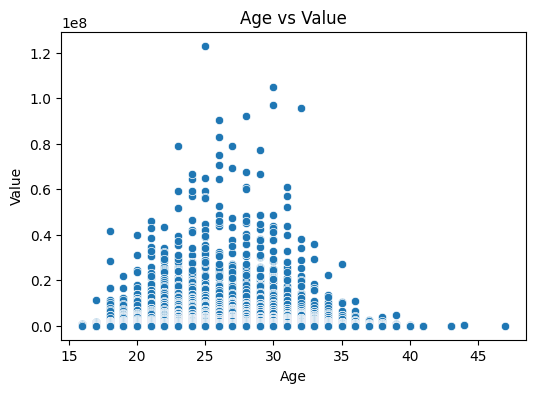

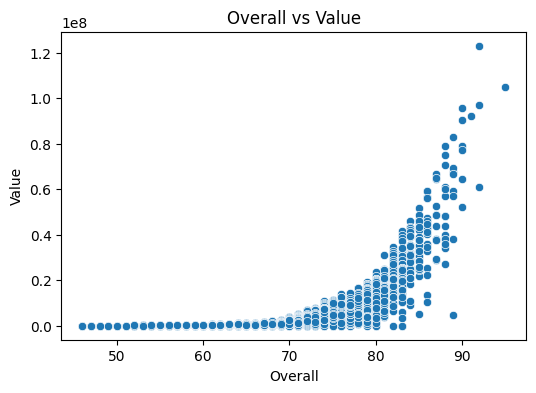

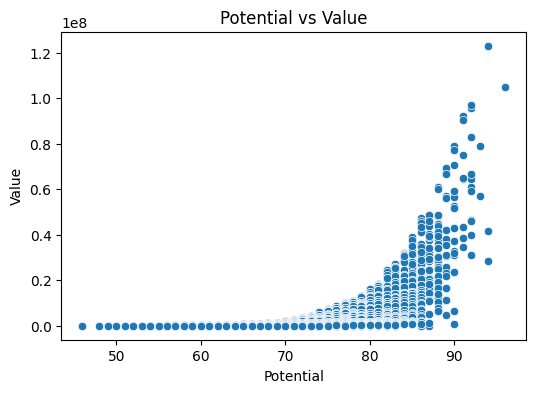

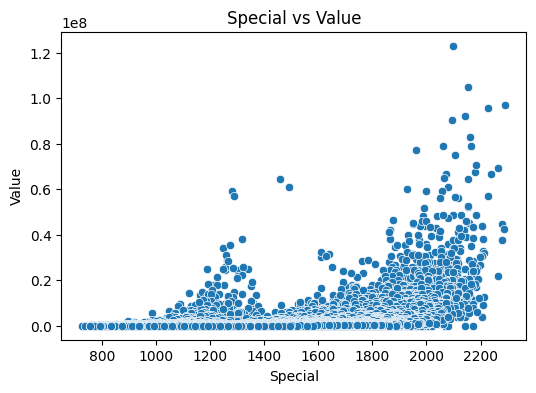

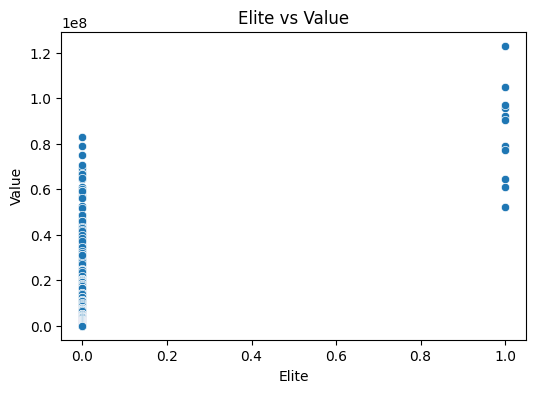

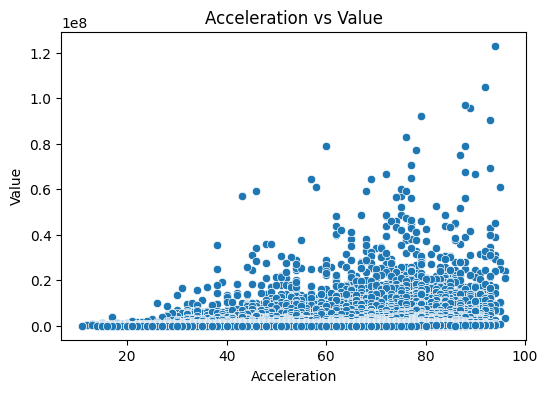

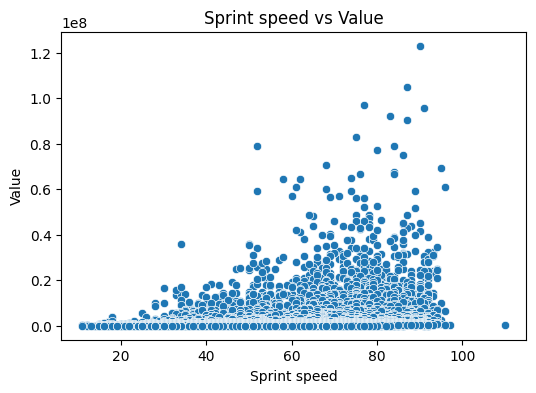

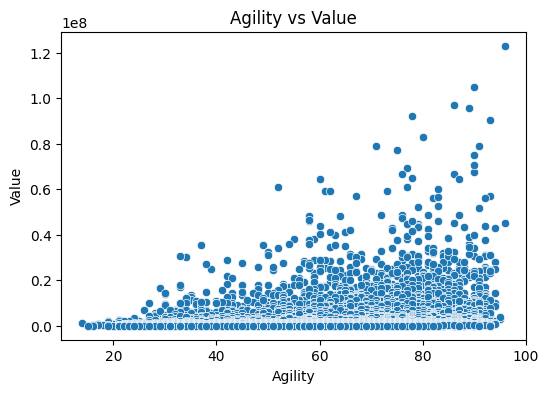

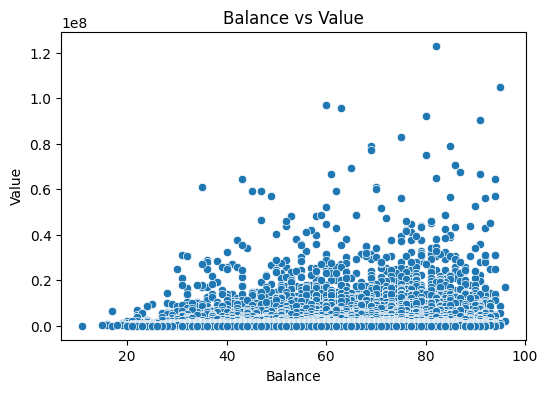

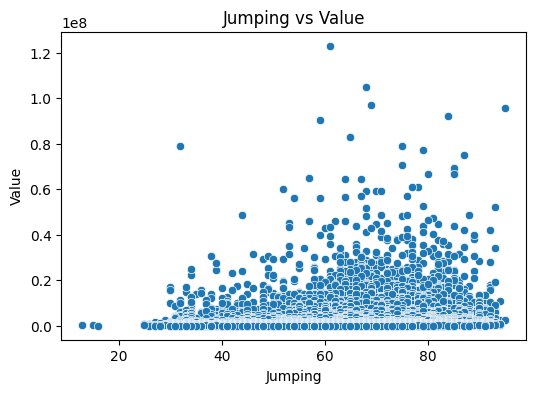

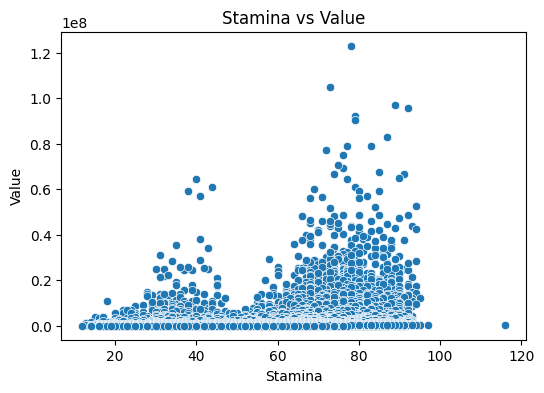

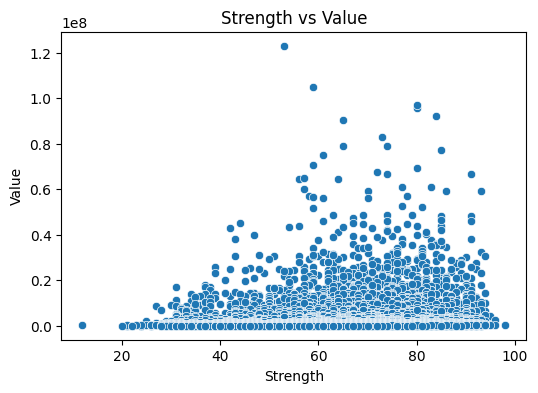

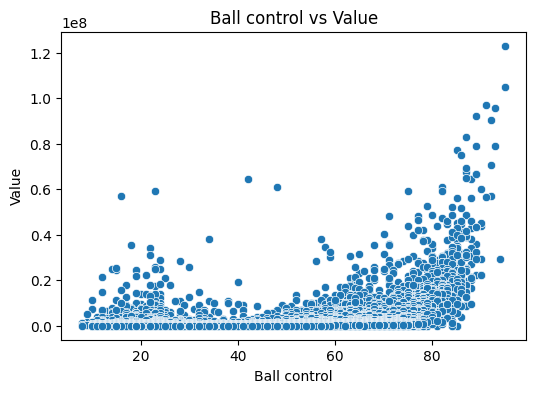

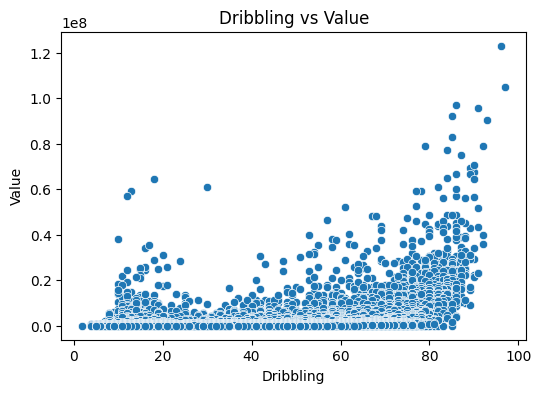

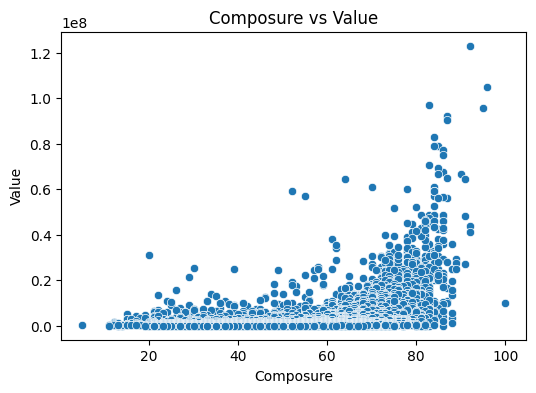

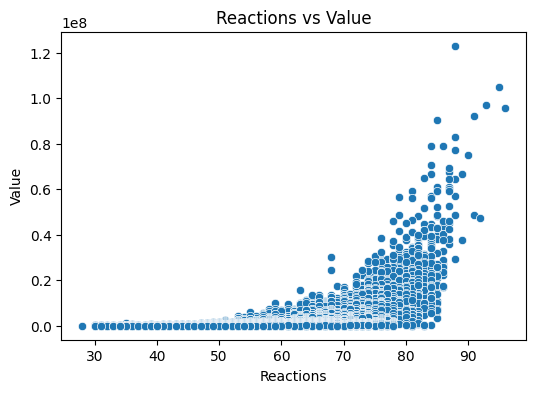

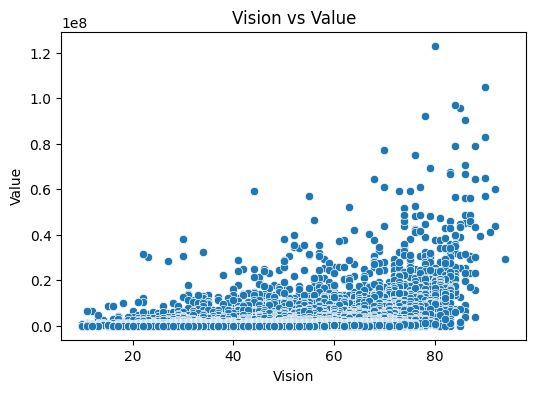

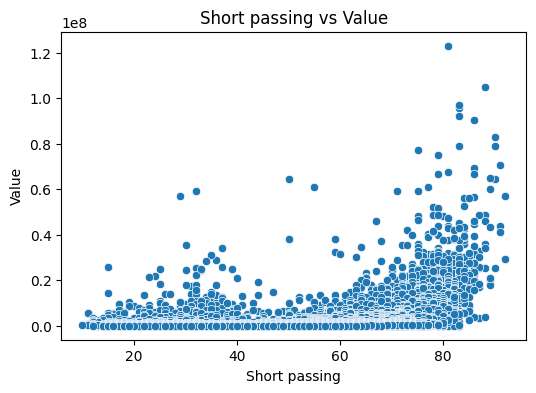

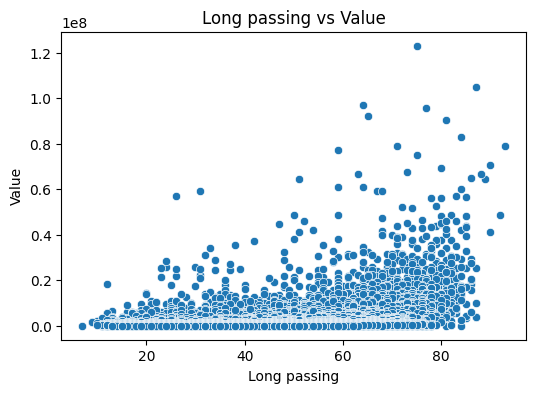

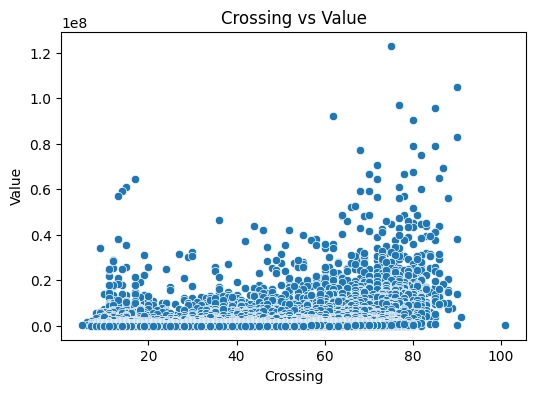

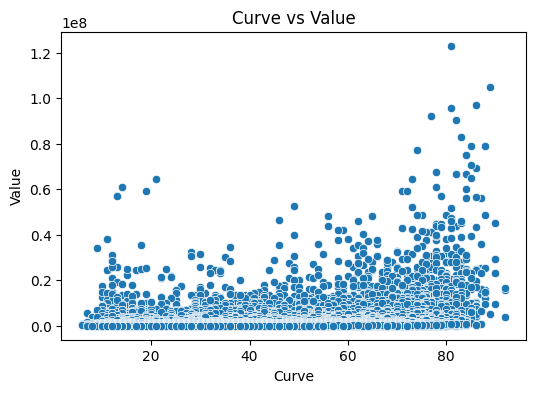

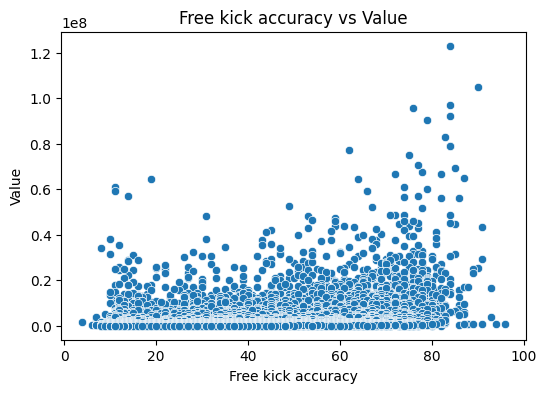

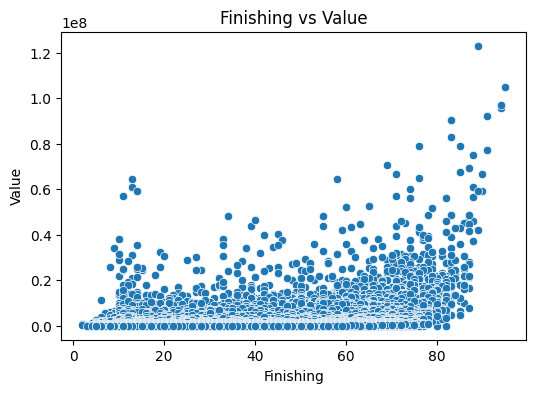

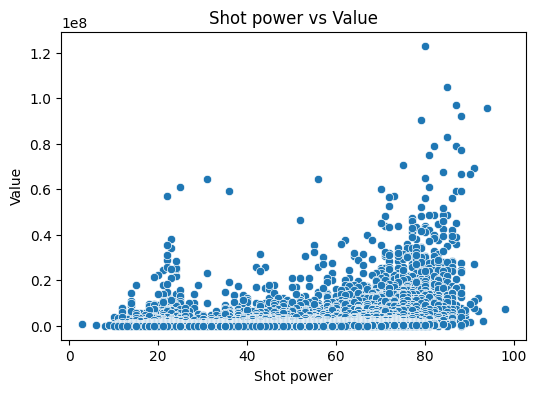

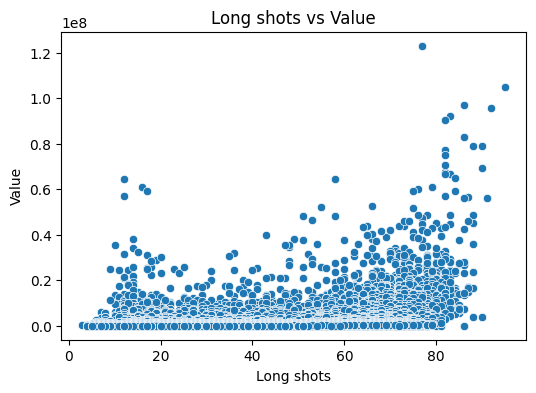

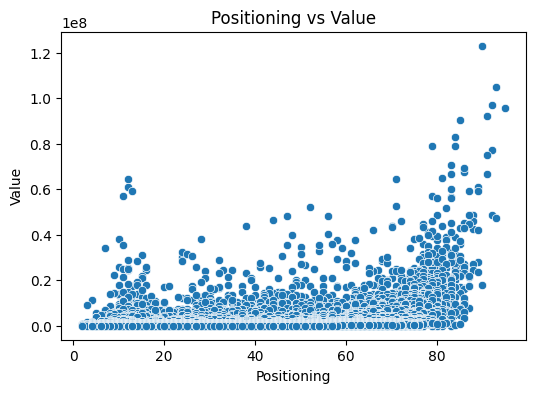

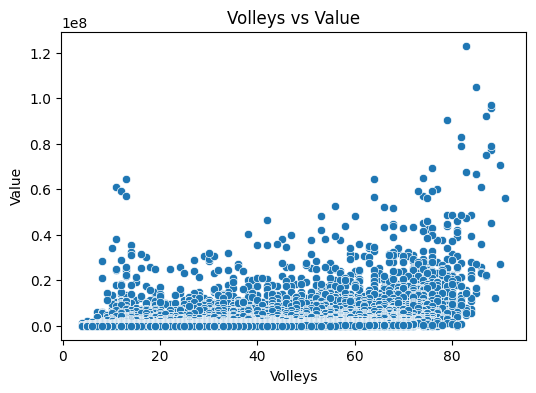

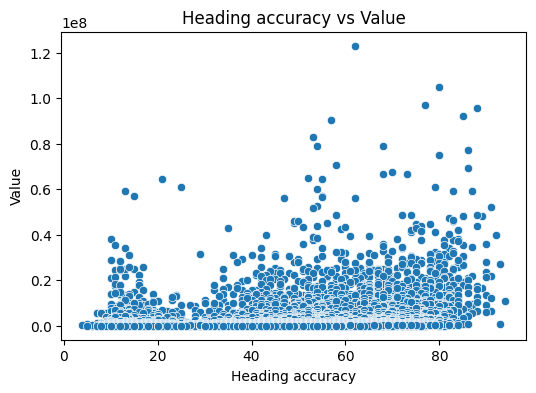

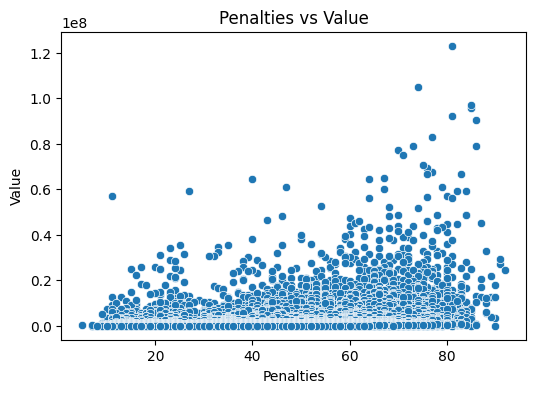

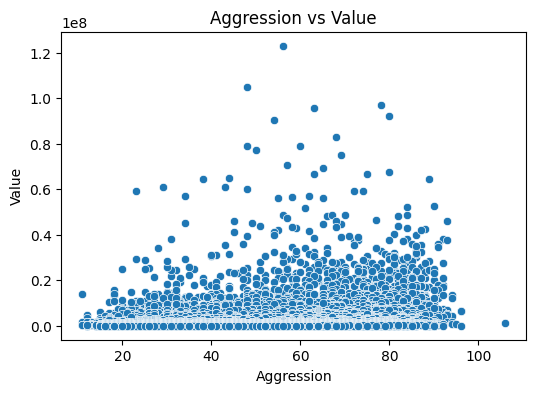

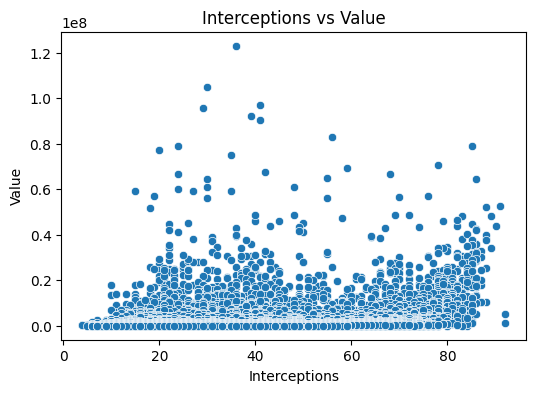

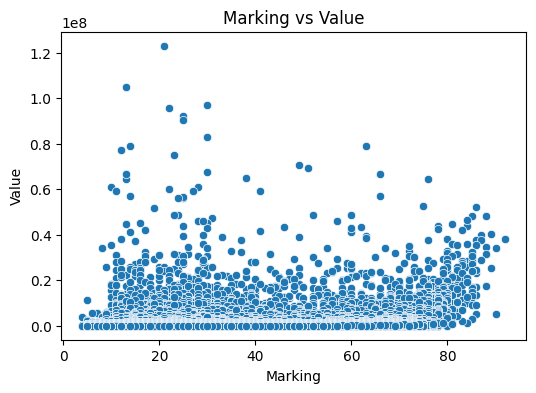

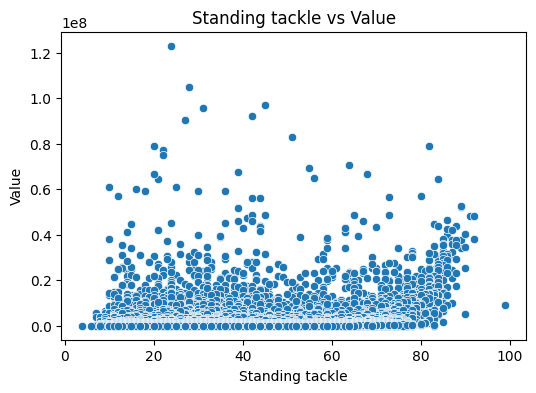

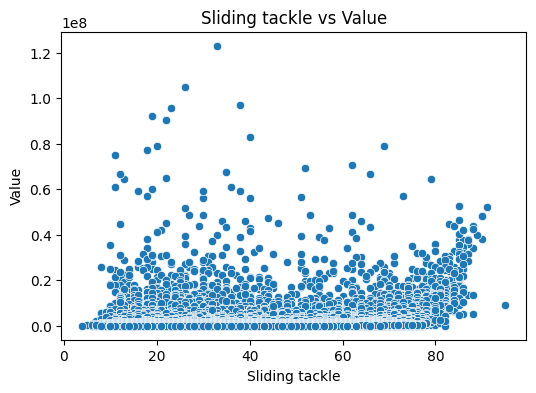

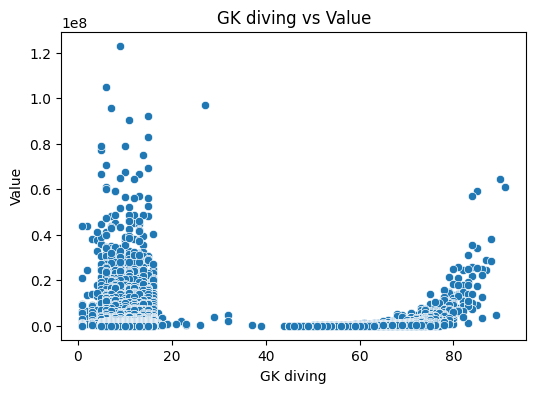

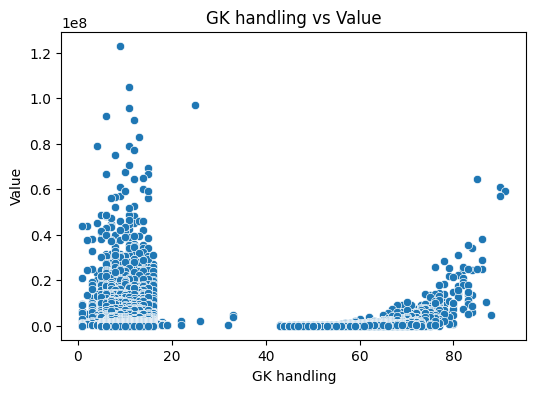

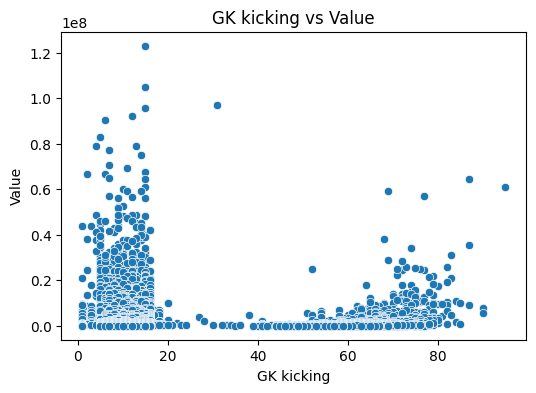

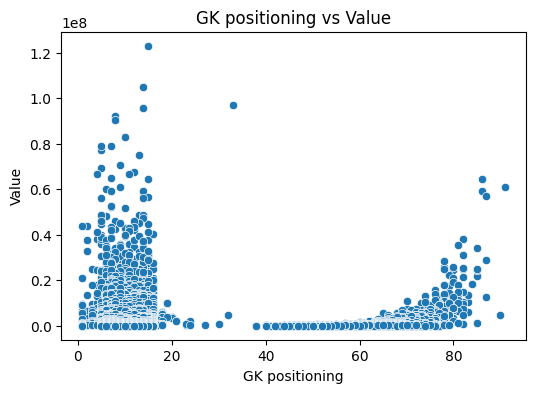

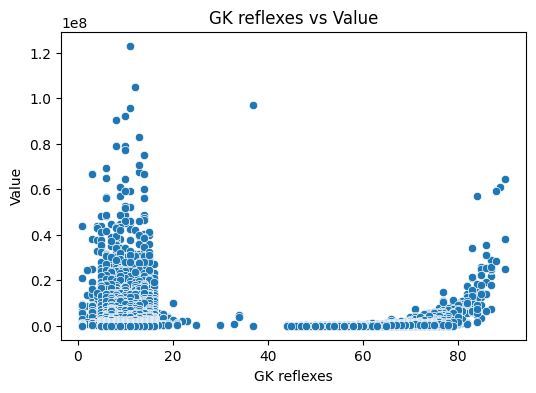

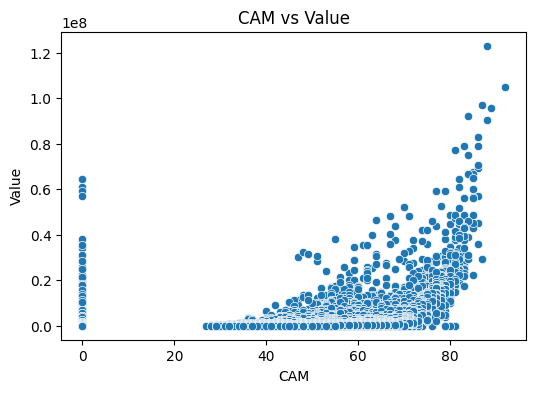

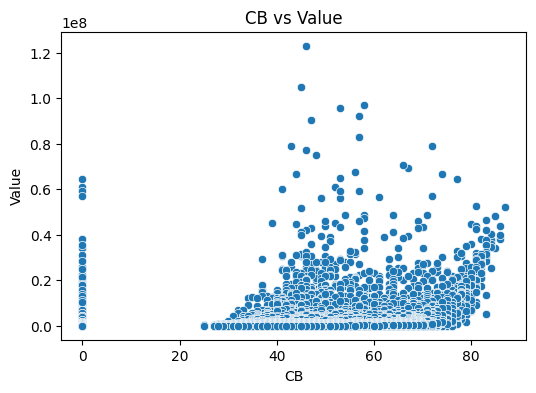

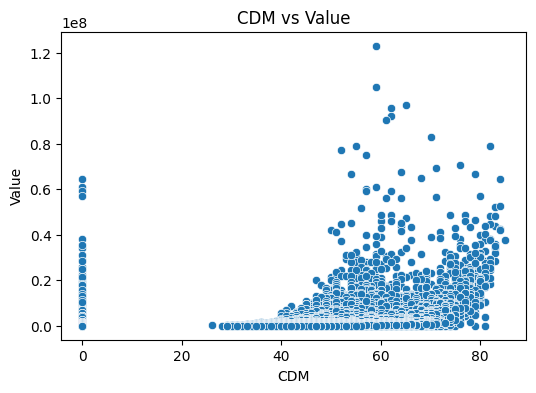

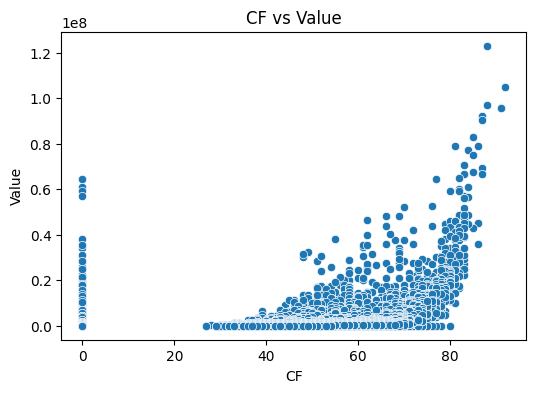

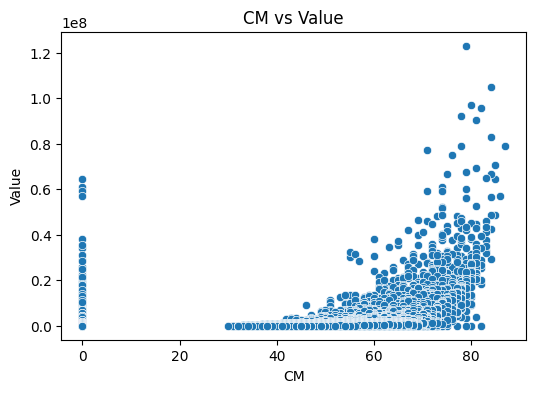

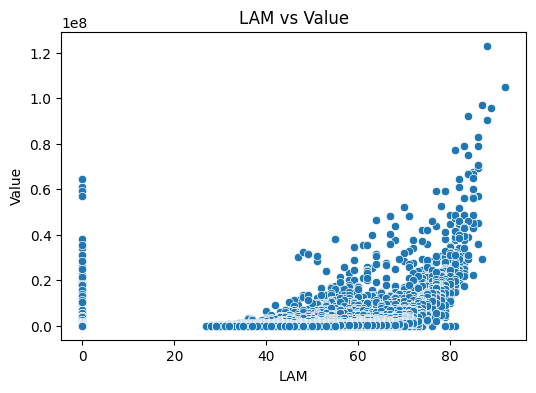

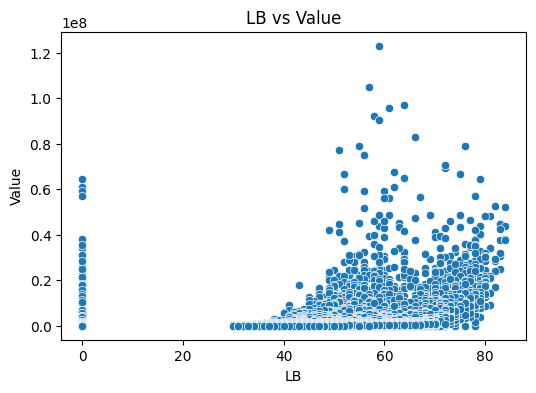

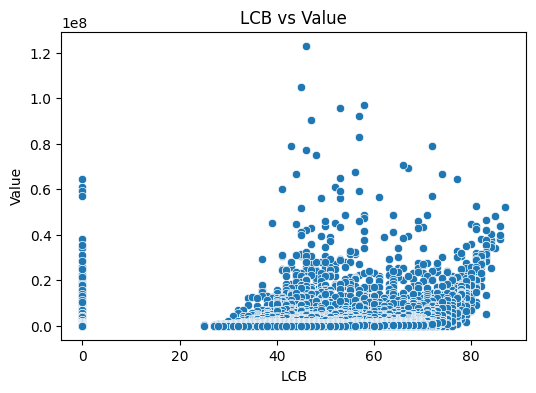

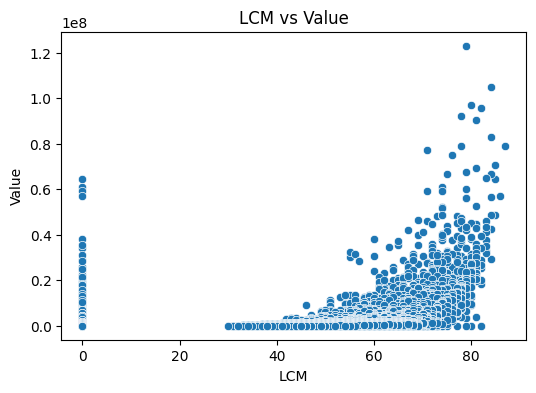

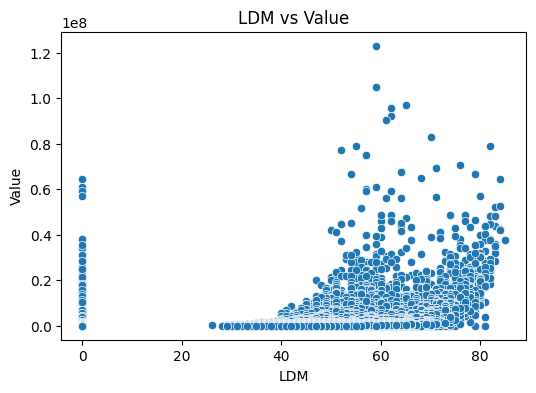

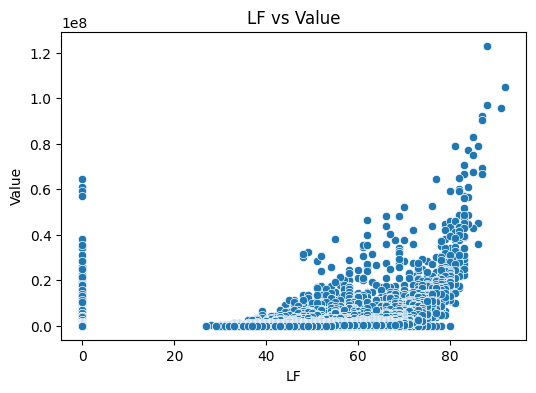

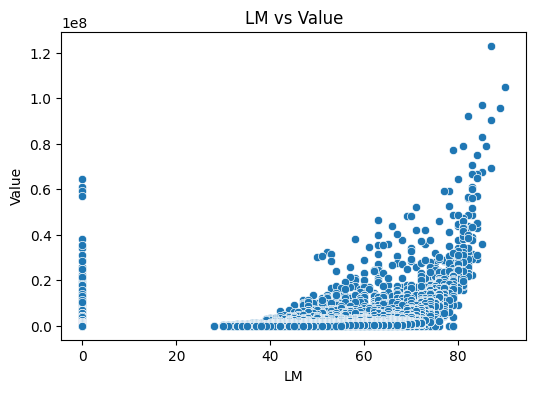

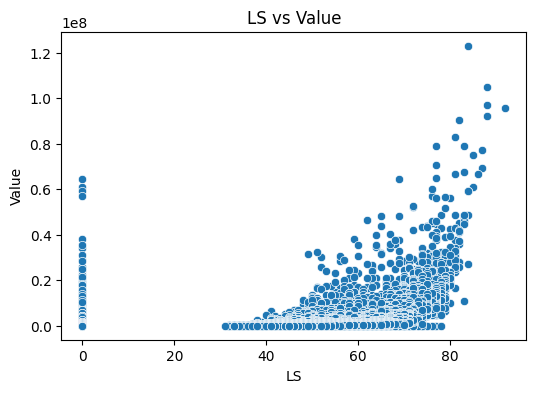

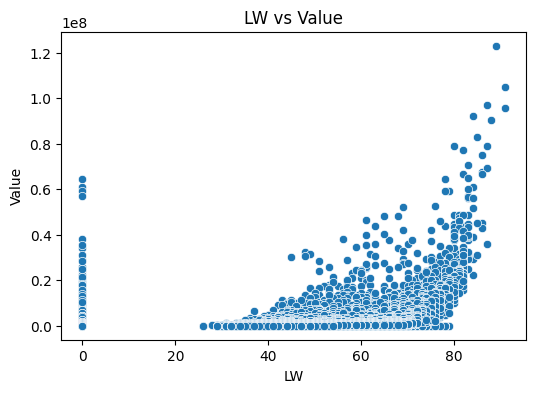

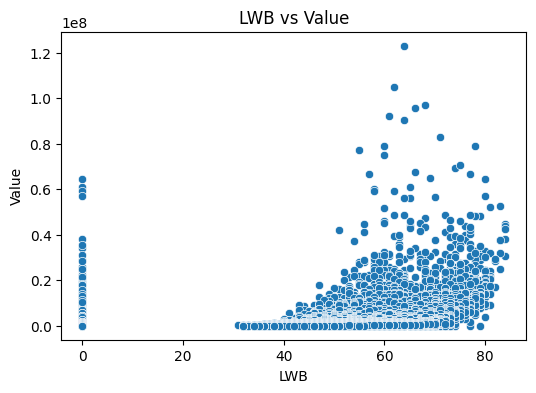

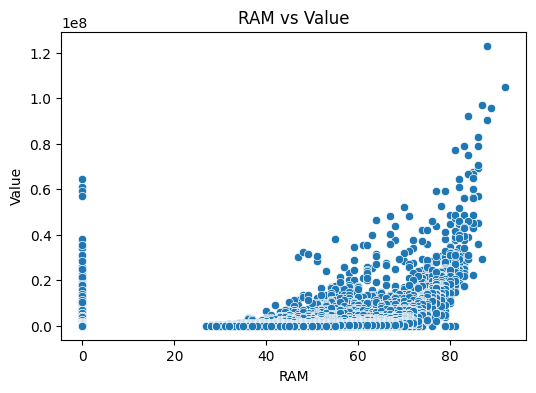

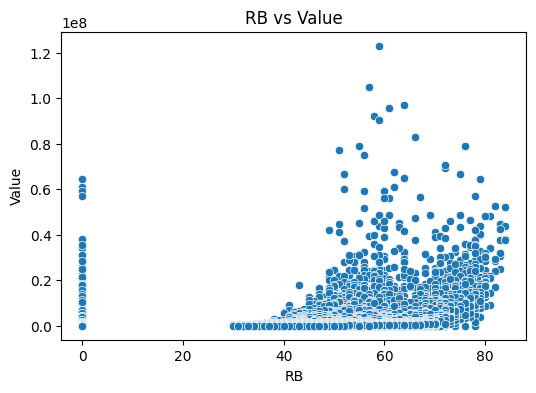

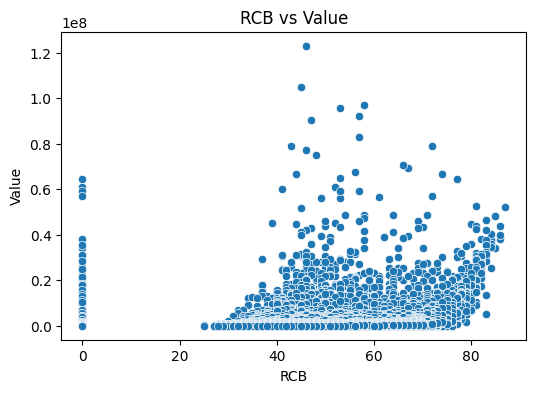

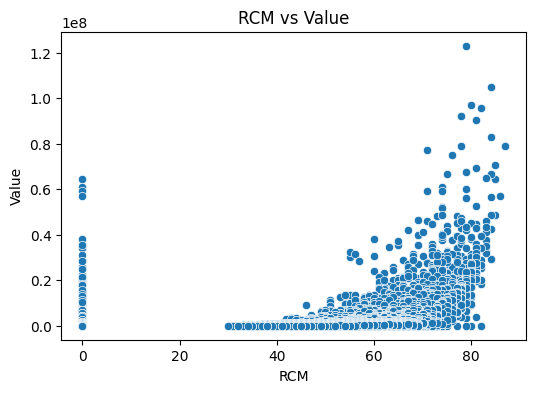

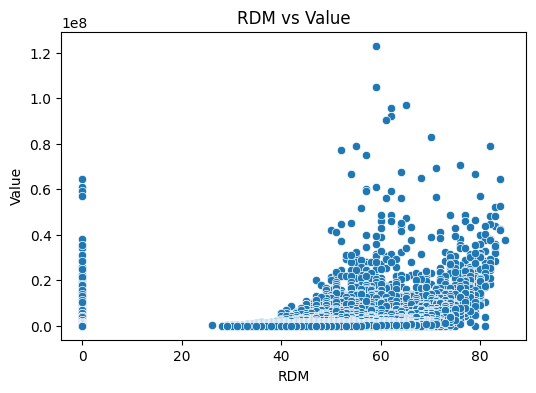

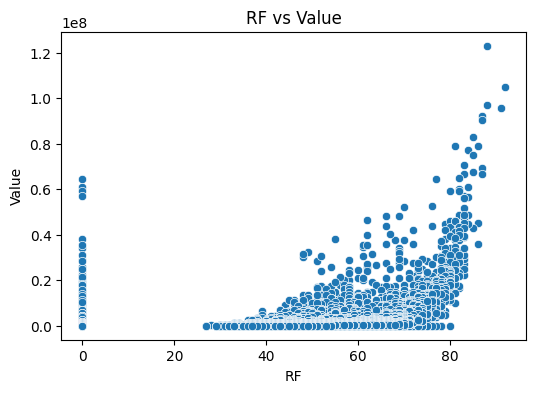

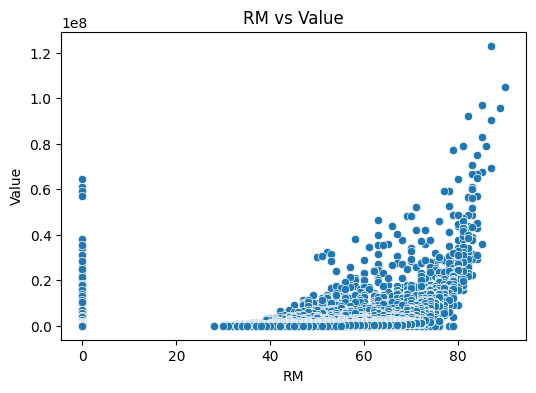

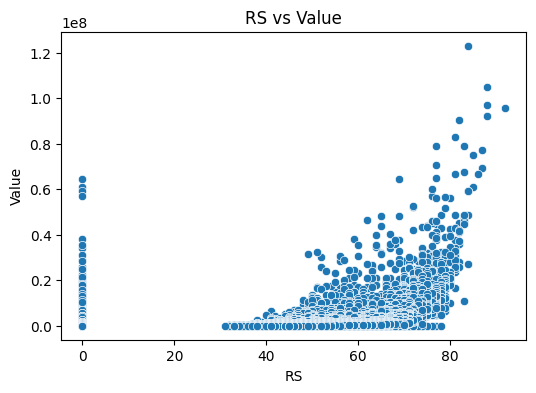

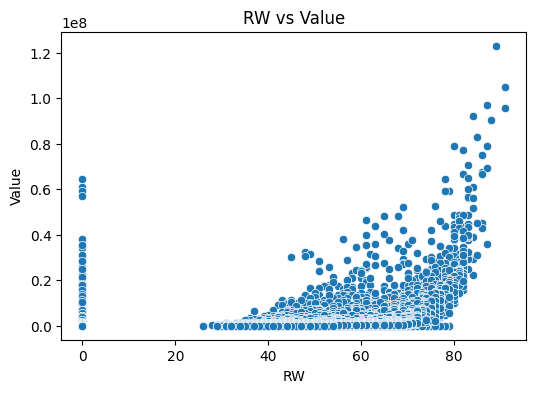

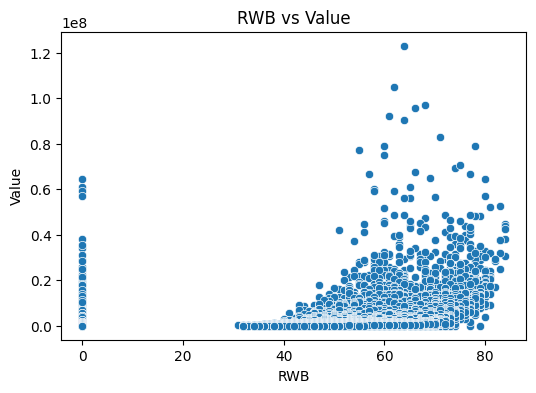

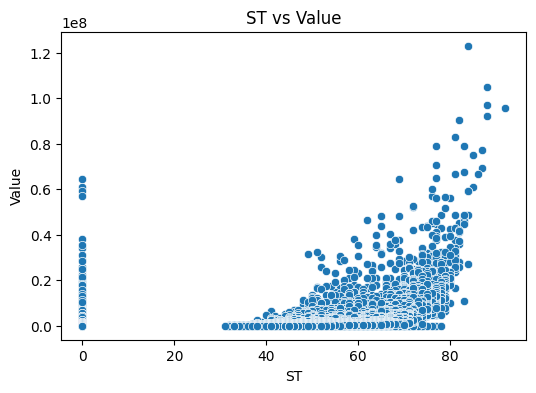

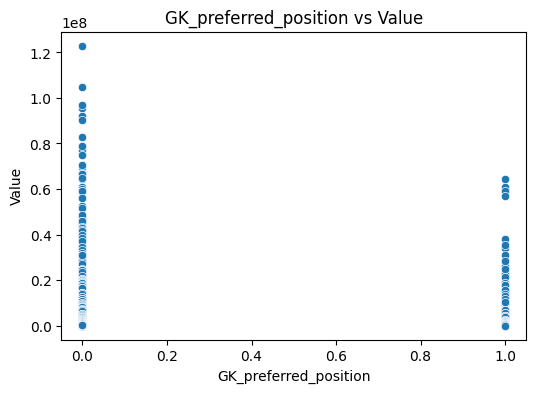

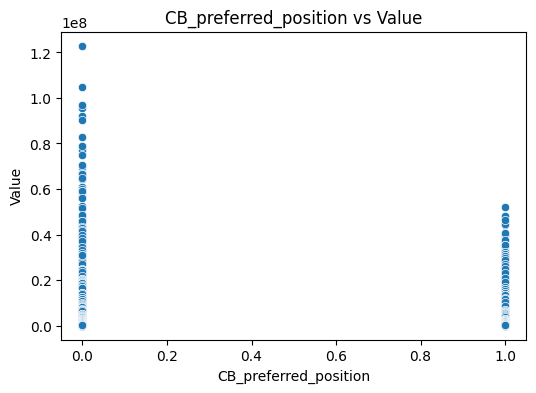

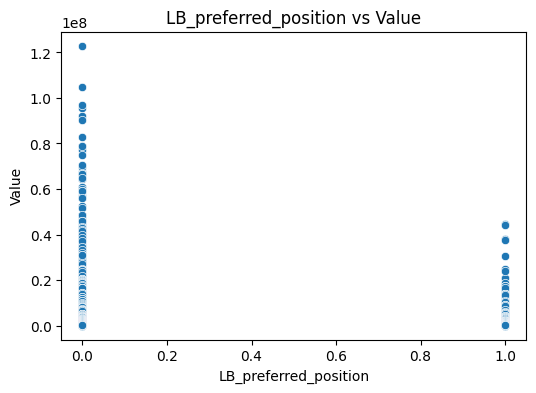

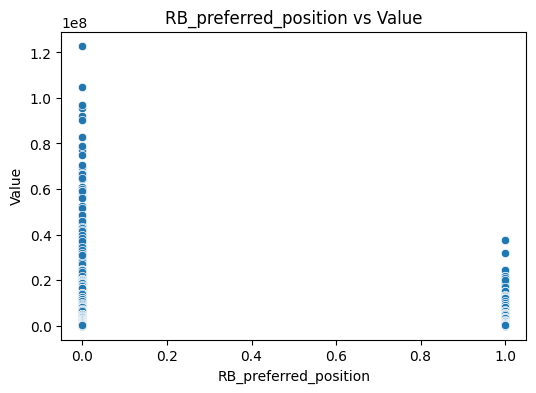

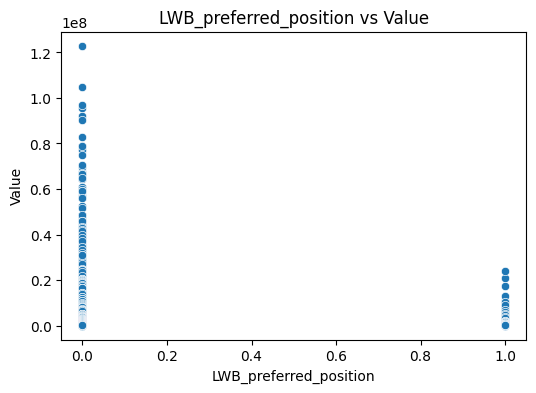

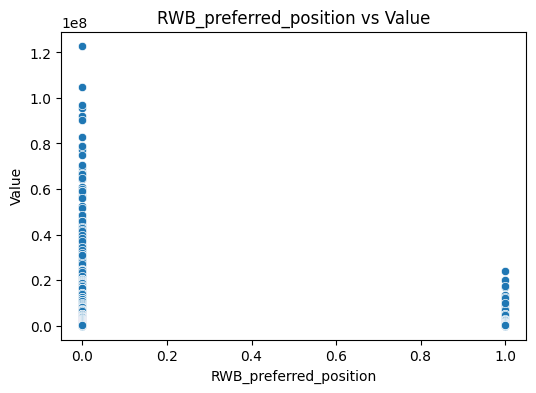

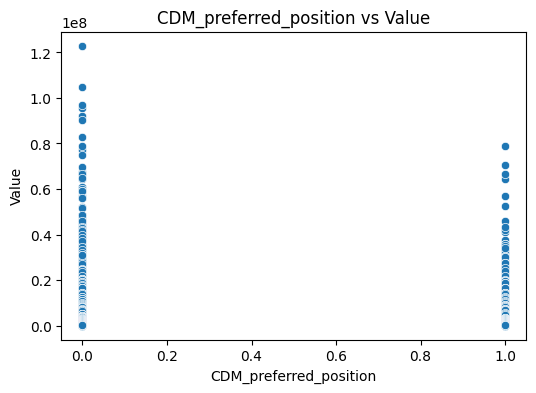

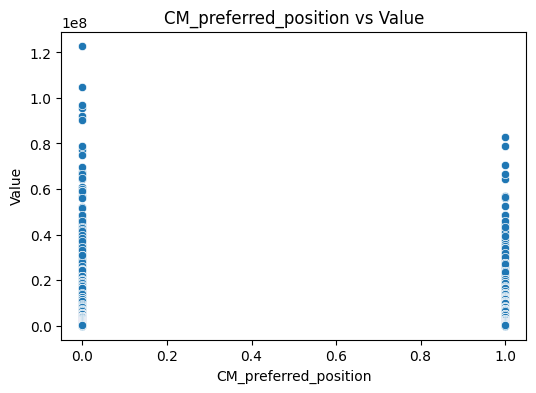

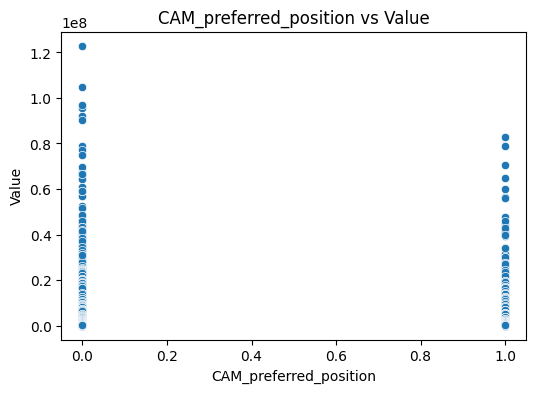

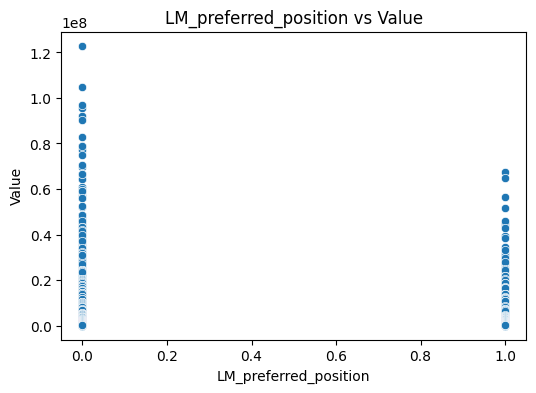

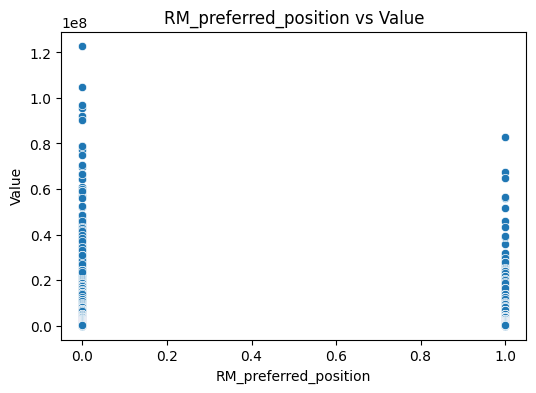

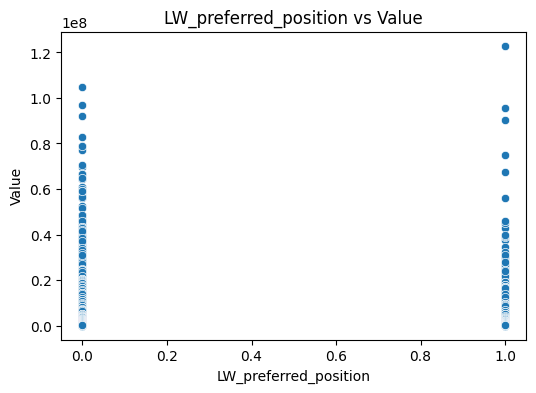

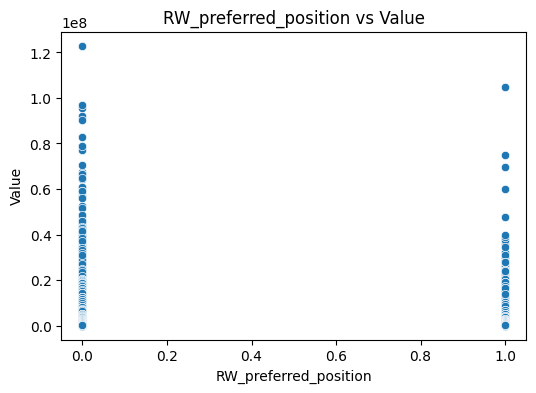

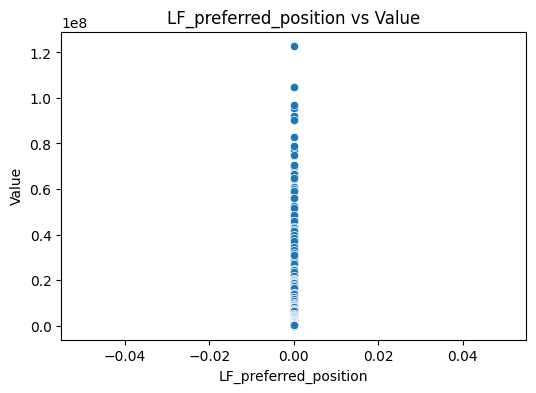

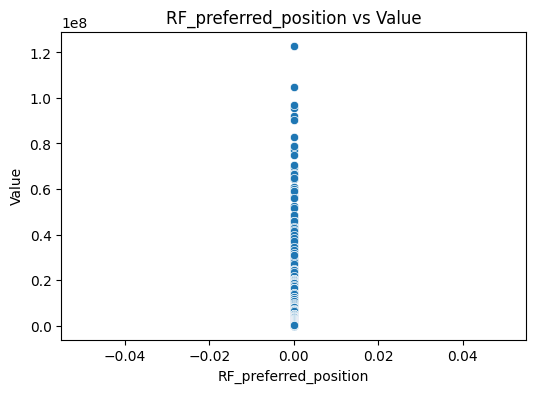

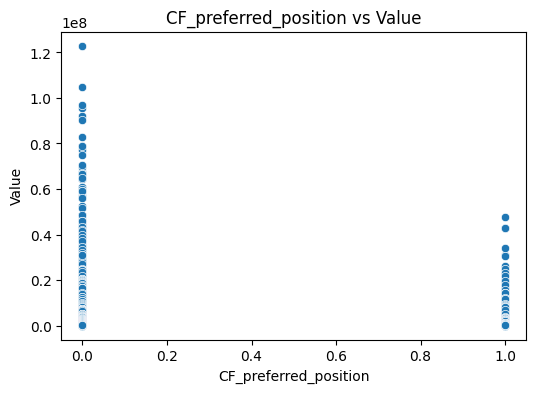

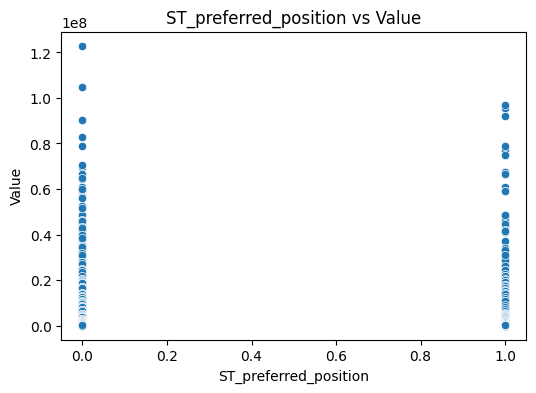

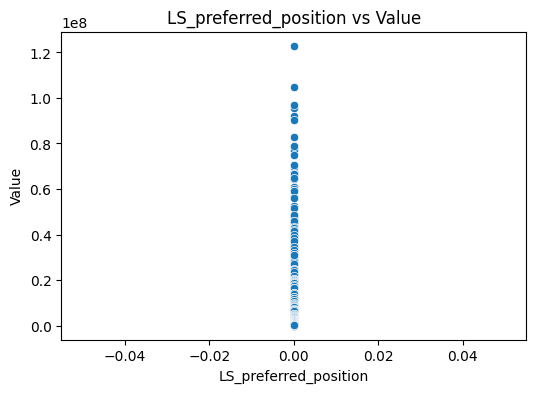

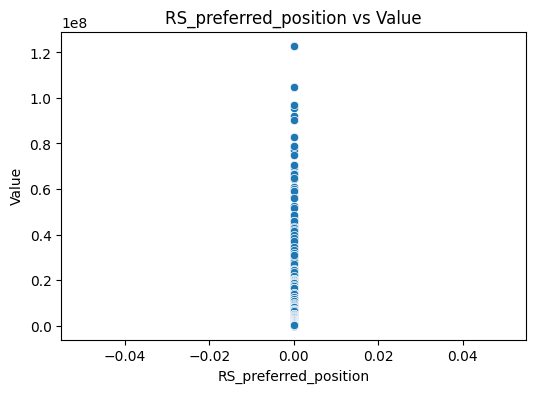

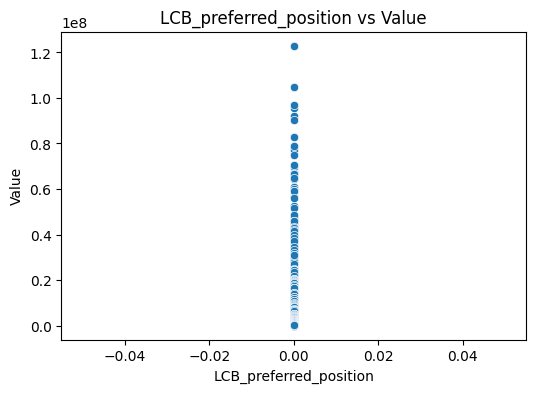

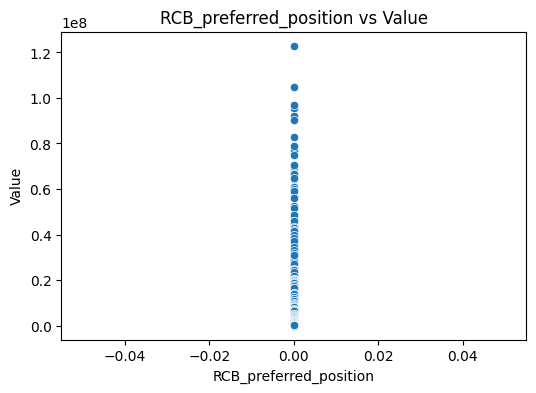

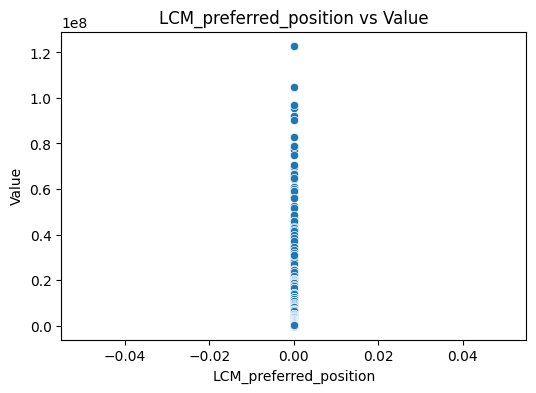

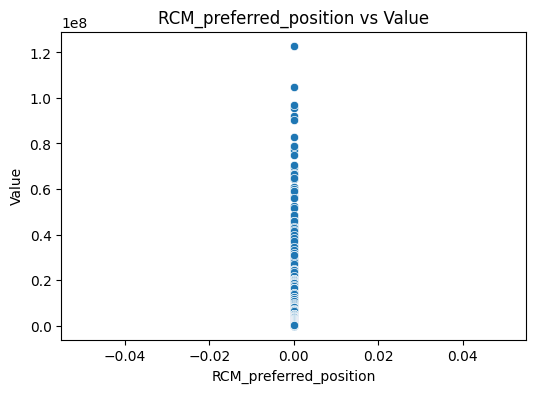

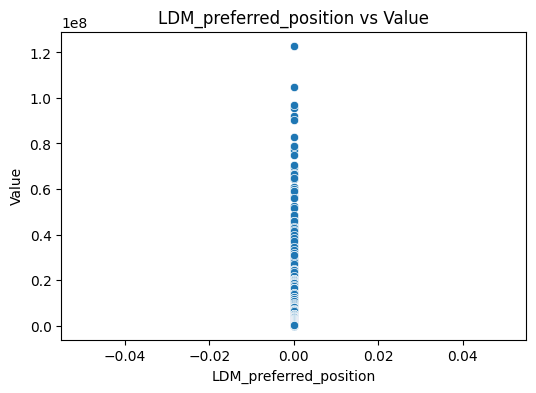

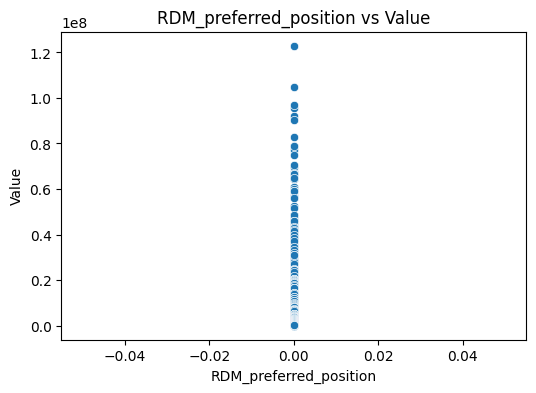

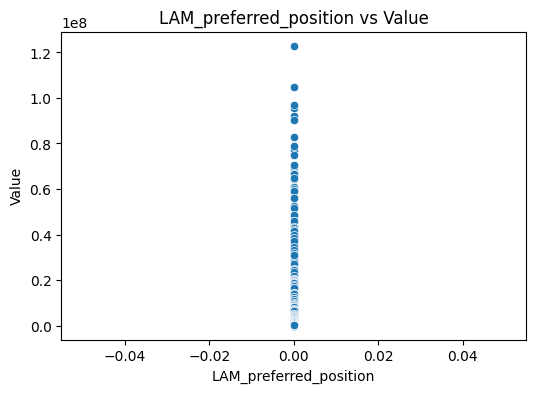

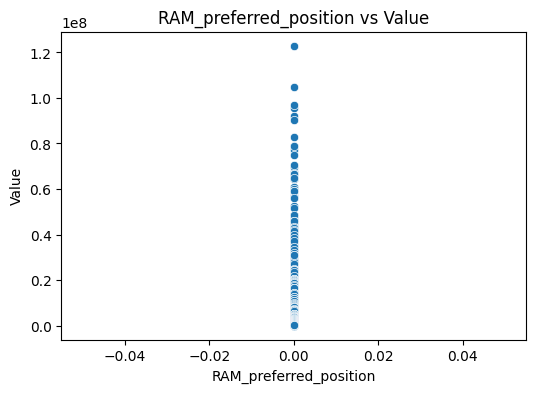

In [14]:

for feature in selected_features:
    plt.figure(figsize=(6, 4))
    sns.scatterplot(x=df[feature], y=df['Value'])
    plt.title(f'{feature} vs Value')
    plt.show()

In [15]:

# Pearson Correlation
from scipy.stats import pearsonr

# List of features to check against target
correlations = {
    feature: pearsonr(df[feature], df['Value'])[0]
    for feature in selected_features
}

correlation_df = pd.DataFrame(
    list(correlations.items()),
    columns=['Feature', 'Pearson Correlation']
)

print(correlation_df.sort_values(by='Pearson Correlation', ascending=False))

                   Feature  Pearson Correlation
1                  Overall             0.625786
2                Potential             0.588258
15               Reactions             0.531027
14               Composure             0.402051
4                    Elite             0.382412
..                     ...                  ...
87  RCM_preferred_position                  NaN
88  LDM_preferred_position                  NaN
89  RDM_preferred_position                  NaN
90  LAM_preferred_position                  NaN
91  RAM_preferred_position                  NaN

[92 rows x 2 columns]


In [16]:
# Dropping numerical features
drop_features = correlation_df[
    abs(correlation_df['Pearson Correlation']) < 0.10
]['Feature'].tolist()

print(drop_features)

df.drop(columns=drop_features, inplace=True)

['Age', 'Marking', 'Sliding tackle', 'GK diving', 'GK handling', 'GK kicking', 'GK positioning', 'GK reflexes', 'GK_preferred_position', 'CB_preferred_position', 'LB_preferred_position', 'RB_preferred_position', 'LWB_preferred_position', 'RWB_preferred_position', 'CDM_preferred_position', 'CM_preferred_position', 'CAM_preferred_position', 'LM_preferred_position', 'RM_preferred_position', 'LW_preferred_position', 'RW_preferred_position', 'CF_preferred_position', 'ST_preferred_position']


In [17]:
"""chi square test"""

preferred_position = [
    feature for feature in preferred_position
    if feature in df.columns
]

cat_features = ['Elite', 'Nationality', 'Club'] + preferred_position

from scipy.stats import chi2_contingency
alpha = 0.05

df['Value_bin'] = pd.qcut(df['Value'], q=4, labels=False)
chi2_results = {}

for col in cat_features:
    contingency = pd.crosstab(df[col], df['Value_bin'])
    chi2_stat, p_val, _, _ = chi2_contingency(contingency)
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'

    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }

chi2_df = pd.DataFrame(chi2_results).T
chi2_df = chi2_df.sort_values(by='p_value')

print(chi2_df)

                       chi2_statistic p_value                    Decision
Nationality               3504.046986     0.0  Reject Null (Keep Feature)
Club                     11889.506395     0.0  Reject Null (Keep Feature)
Elite                        33.89165     0.0  Reject Null (Keep Feature)
LF_preferred_position             0.0     1.0  Accept Null (Drop Feature)
RF_preferred_position             0.0     1.0  Accept Null (Drop Feature)
LS_preferred_position             0.0     1.0  Accept Null (Drop Feature)
RS_preferred_position             0.0     1.0  Accept Null (Drop Feature)
LCB_preferred_position            0.0     1.0  Accept Null (Drop Feature)
RCB_preferred_position            0.0     1.0  Accept Null (Drop Feature)
LCM_preferred_position            0.0     1.0  Accept Null (Drop Feature)
RCM_preferred_position            0.0     1.0  Accept Null (Drop Feature)
LDM_preferred_position            0.0     1.0  Accept Null (Drop Feature)
RDM_preferred_position            0.0 

In [18]:
## Droping categorical features
drop_cat = chi2_df[
    chi2_df['Decision'] == 'Accept Null (Drop Feature)'
].index.tolist()

print(drop_cat)

df.drop(columns=drop_cat, inplace=True)
df.drop(columns='Value_bin', inplace=True)

selected_features = [
    col for col in selected_features
    if col in df.columns
]

['LF_preferred_position', 'RF_preferred_position', 'LS_preferred_position', 'RS_preferred_position', 'LCB_preferred_position', 'RCB_preferred_position', 'LCM_preferred_position', 'RCM_preferred_position', 'LDM_preferred_position', 'RDM_preferred_position', 'LAM_preferred_position', 'RAM_preferred_position']


In [19]:
# scaling
from sklearn.preprocessing import StandardScaler
cols = [
    col for col in selected_features
    if df[col].nunique() > 2
]
scaler = StandardScaler()
df[cols]=scaler.fit_transform(df[cols])
print(df.head())


final_df = df.copy()

                Name Nationality   Overall  Potential                 Club  \
0  Cristiano Ronaldo    Portugal  3.399283   3.410064       Real Madrid CF   
1           L. Messi   Argentina  4.114858   4.065558         FC Barcelona   
2             Neymar      Brazil  3.685513   3.737811  Paris Saint-Germain   
3          L. Suárez     Uruguay  3.685513   3.410064         FC Barcelona   
4           M. Neuer     Germany  3.685513   3.410064     FC Bayern Munich   

       Value    Wage   Special  Acceleration  Aggression  ...       RCB  \
0   95500000  565000  2.329301      1.635276    0.409890  ...  0.177085   
1  105000000  565000  2.057386      1.836395   -0.448218  ... -0.203956   
2  123000000  280000  1.858961      1.970474    0.009440  ... -0.156326   
3   97000000  510000  2.560796      1.568237    1.267997  ...  0.415236   
4   61000000  230000 -0.371477     -0.442951   -1.535154  ... -2.347311   

        RCM       RDM        RF        RM        RS        RW       RWB  \
0  1.

In [20]:
## now using this dataframe we will create a ML model

from sklearn.model_selection import train_test_split

x = final_df.drop(["Name", "Nationality", "Club", "Value"],axis=1)
y = final_df['Value']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size =0.2, random_state =42)

In [21]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [22]:
# Prediction

y_pred = model.predict(x_test)

from sklearn.metrics import r2_score
r2 = r2_score(y_test,y_pred)

n = x_test.shape[0]
p = x_test.shape[1]
adjusted_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))
print(f"R2 score : {r2}")
print(f"Adjusted R2 score : {adjusted_r2}")

R2 score : 0.7982804136850034
Adjusted R2 score : 0.794973535220823


In [23]:
# Overfitting / Underfitting check

# Training predictions
y_train_pred = model.predict(x_train)

# Testing predictions
y_test_pred = model.predict(x_test)

# R² scores
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print("Training R²:", train_r2)
print("Testing R² :", test_r2)
print(f"Generalization Gap {abs(train_r2 - test_r2)}")

Training R²: 0.767226034459006
Testing R² : 0.7982804136850034
Generalization Gap 0.03105437922599741


In [24]:
# Saving Model Files (.pkl)
import joblib

joblib.dump(model, "football_market_value_model.pkl")
joblib.dump(scaler, "scalar.pkl")
joblib.dump(x.columns.tolist(), "columns.pkl")

print("All files saved successfully.")
print("Number of features:", len(x.columns))
print("Features:")
print(x.columns.tolist())

All files saved successfully.
Number of features: 58
Features:
['Overall', 'Potential', 'Wage', 'Special', 'Acceleration', 'Aggression', 'Agility', 'Balance', 'Ball control', 'Composure', 'Crossing', 'Curve', 'Dribbling', 'Finishing', 'Free kick accuracy', 'Heading accuracy', 'Interceptions', 'Jumping', 'Long passing', 'Long shots', 'Penalties', 'Positioning', 'Reactions', 'Short passing', 'Shot power', 'Sprint speed', 'Stamina', 'Standing tackle', 'Strength', 'Vision', 'Volleys', 'CAM', 'CB', 'CDM', 'CF', 'CM', 'LAM', 'LB', 'LCB', 'LCM', 'LDM', 'LF', 'LM', 'LS', 'LW', 'LWB', 'RAM', 'RB', 'RCB', 'RCM', 'RDM', 'RF', 'RM', 'RS', 'RW', 'RWB', 'ST', 'Elite']
